# 05 — Model Building
**Project:** Telco Customer Churn Predictor  
**Author:** Ibtissam Bukhari  
**Goal:** Train multiple ML models, evaluate them, tune the best one,
and save the final model for the Streamlit app.

---

## Flow
1. Separate X and y
2. Train test split
3. Train multiple models
4. Evaluate and compare
5. Hyperparameter tuning on best model
6. Final evaluation on test data
7. Save model

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score,
                             confusion_matrix, classification_report)
import joblib
from xgboost import XGBClassifier
df = pd.read_csv('../data/processed/telco_prepared.csv')

print("Data loaded")
print(f"Shape: {df.shape}")

Data loaded
Shape: (7010, 30)


## Step 1 — Separate X and y
X = all feature columns (what model learns from)
y = Churn column (what model predicts)

In [3]:
X = df.drop(columns=['Churn'])
y = df['Churn']

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Churn distribution:\n", y.value_counts())

X shape: (7010, 29)
y shape: (7010,)
Churn distribution:
 Churn
0    5153
1    1857
Name: count, dtype: int64


## Step 2 — Train Test Split
Split data into 80% training and 20% testing.
Test data is completely unseen during training.
This gives us an honest evaluation of model performance.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("\nTrain churn distribution:\n", y_train.value_counts())
print("\nTest churn distribution:\n", y_test.value_counts())

X_train shape: (5608, 29)
X_test shape: (1402, 29)

Train churn distribution:
 Churn
0    4122
1    1486
Name: count, dtype: int64

Test churn distribution:
 Churn
0    1031
1     371
Name: count, dtype: int64


## Step 3 — Train Multiple Models
We train three models and compare their performance.
We use class_weight='balanced' to handle class imbalance
without creating fake synthetic data.

In [9]:
models = {
    'Logistic Regression': LogisticRegression(
        class_weight='balanced', random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(
        class_weight='balanced', random_state=42),
    'XGBoost': XGBClassifier(
        scale_pos_weight=5153/1857, random_state=42, eval_metric='logloss')
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    results[name] = {
        'Accuracy' : accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall'   : recall_score(y_test, y_pred),
        'F1 Score' : f1_score(y_test, y_pred)
    }
    print(f"{name} trained")

print("\nAll models trained")

Logistic Regression trained
Random Forest trained
XGBoost trained

All models trained


In [10]:
results


{'Logistic Regression': {'Accuracy': 0.746077032810271,
  'Precision': 0.5136116152450091,
  'Recall': 0.7628032345013477,
  'F1 Score': 0.613882863340564},
 'Random Forest': {'Accuracy': 0.7774607703281027,
  'Precision': 0.6057347670250897,
  'Recall': 0.4555256064690027,
  'F1 Score': 0.52},
 'XGBoost': {'Accuracy': 0.7503566333808844,
  'Precision': 0.5231788079470199,
  'Recall': 0.6388140161725068,
  'F1 Score': 0.5752427184466019}}

## Step 5 — Confusion Matrix
Visualize exactly where our best model makes mistakes.
Which churners did it miss? Which did it catch?

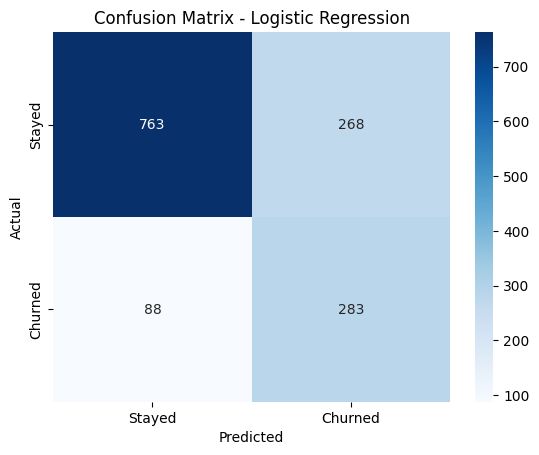

In [11]:
best_model = models['Logistic Regression']
y_pred_best = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_best)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Stayed', 'Churned'],
            yticklabels=['Stayed', 'Churned'])

plt.title('Confusion Matrix - Logistic Regression')
plt.ylabel('Actual')
plt.xlabel('Predicted')

plt.savefig('../outputs/figures/08_confusion_matrix.png', dpi=150)
plt.show()

## Step 6 — Hyperparameter Tuning
Find the best settings for Logistic Regression
using GridSearchCV with cross validation.
We optimize for Recall — catching churners is our priority.

In [12]:
from sklearn.model_selection import GridSearchCV

param_grid = {'C': [0.01, 0.1, 1, 10, 100]}

grid_search = GridSearchCV(
    LogisticRegression(class_weight='balanced', 
                       random_state=42, max_iter=1000),
    param_grid,
    cv=5,
    scoring='recall',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best C value:", grid_search.best_params_)
print("Best cross validation recall:", round(grid_search.best_score_, 4))

Best C value: {'C': 0.01}
Best cross validation recall: 0.8049


In [13]:
final_model = LogisticRegression(
    C=0.01,
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)

final_model.fit(X_train, y_train)
y_pred_final = final_model.predict(X_test)

print("Final Model Performance:")
print("Accuracy :", round(accuracy_score(y_test, y_pred_final), 4))
print("Precision:", round(precision_score(y_test, y_pred_final), 4))
print("Recall   :", round(recall_score(y_test, y_pred_final), 4))
print("F1 Score :", round(f1_score(y_test, y_pred_final), 4))

Final Model Performance:
Accuracy : 0.7411
Precision: 0.5072
Recall   : 0.7628
F1 Score : 0.6093


In [14]:
joblib.dump(final_model, '../models/churn_model.pkl')

print("Model saved to models/churn_model.pkl")

Model saved to models/churn_model.pkl


## Summary — Model Building Complete

### Models Trained
- Logistic Regression → Recall: 76.3%, Accuracy: 74.6%
- Random Forest       → Recall: 45.6%, Accuracy: 77.7%
- XGBoost             → Recall: 63.9%, Accuracy: 75.0%

### Why Logistic Regression Won
- Recall is most important for churn prediction
- Missing a churner costs more than a false alarm
- Logistic Regression catches 76% of actual churners

### Final Model Performance on Unseen Test Data
- Accuracy  : 74.1%
- Precision : 50.7%
- Recall    : 76.3%
- F1 Score  : 60.9%

### Key Decisions
- Used class_weight='balanced' to handle imbalance
- Used GridSearchCV to find best C=0.01
- Optimized for Recall not Accuracy

### Next → app/app.py (Streamlit Web App)